# Where is the Google Merchandise Store losing revenue?

This notebook answers the project's business question from the dbt marts: where conversion and revenue fall short across devices, channels, visitor types, the checkout funnel, products and customers, whether those gaps are statistically real, and what closing part of them would be worth.

**Data:** Google Analytics 4 sample e-commerce export for the Google Merchandise Store, 1 November 2020 to 31 January 2021 (92 days), modelled in BigQuery with dbt and exported by `analysis/export_marts.py` to `data/exports/`.

**Definitions** (full list in `docs/business_case.md`):
- **Conversion rate:** sessions with a purchase event / sessions.
- **Order value:** revenue of a de-duplicated order. Purchases without a usable transaction ID are excluded from orders and revenue (see the reconciliation below).
- **Revenue per conversion:** order revenue / sessions with a purchase. It is slightly below order value because unidentified purchases count as conversions but carry no revenue, which keeps the dollar estimates conservative.
- **Funnel steps** use a closed funnel: a session counts at a step only if it also completed every earlier step. GA4 does not force steps into order, so an open count can show more sessions at a later step than an earlier one.
- **Cart abandonment:** sessions that added to cart without purchasing in the same session / sessions that added to cart.

**Statistics:** 95% Wilson intervals for rates, two-proportion z-tests for differences with Holm adjustment within each family of tests, and bootstrap intervals with Mann-Whitney tests for order values. Helpers are in `analysis/conversion_stats.py`.

Run from the repository root: `jupyter nbconvert --to notebook --execute --inplace notebooks/conversion_analysis.ipynb`

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "analysis"))
import conversion_stats as cs

DATA = Path(os.environ.get("EXPORT_DIR", ROOT / "data" / "exports"))
OUT = DATA / "analysis"
IMAGES = Path(os.environ.get("IMAGE_DIR", ROOT / "images"))
OUT.mkdir(parents=True, exist_ok=True)
IMAGES.mkdir(parents=True, exist_ok=True)

sessions = pd.read_csv(DATA / "daily_sessions.csv", parse_dates=["session_date"])
sessions["month"] = sessions["session_date"].dt.to_period("M").astype(str)
orders = pd.read_csv(DATA / "orders.csv", parse_dates=["order_date"])
products = pd.read_csv(DATA / "product_monthly.csv")
buyers = pd.read_csv(DATA / "buyers.csv")
segments = pd.read_csv(DATA / "customer_segments.csv")
recon = pd.read_csv(DATA / "purchase_reconciliation.csv")

pd.options.display.float_format = "{:,.4f}".format
pct = lambda x: f"{x:.2%}"
pp = lambda x: f"{x * 100:+.2f} pp"
usd = lambda x: f"${x:,.0f}"

# Chart style: one recessive grid, text in neutral ink, three validated series colours.
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK, "font.size": 10, "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
print(f"{sessions['sessions'].sum():,} sessions, {len(orders):,} orders, "
      f"{sessions['session_date'].min():%d %b %Y} to {sessions['session_date'].max():%d %b %Y}")

360,129 sessions, 4,451 orders, 01 Nov 2020 to 31 Jan 2021


## 1. Data quality

Before measuring revenue, raw purchase events are split into counted orders, repeat events for an order already counted, and purchases with no usable transaction ID. Only counted orders enter revenue, order value and the dollar estimates.

Two traffic-source problems are also measured here, because they change how channels look:
- **Self-referrals:** sessions whose referrer is the store's own domain. A visit that restarts on the store's site, often on return from checkout, is logged as a new session referred by the store. In a live GA4 property this is fixed by listing the store's domains as unwanted referrals.
- **Sessions with no recorded source:** kept as *Not recorded* and left out of channel comparisons, since they cannot be assigned to a channel.

In [2]:
r = recon.sum(numeric_only=True)
quality = pd.DataFrame({
    "events": [r.purchase_events, r.orders, r.duplicate_events, r.unidentified_events],
    "revenue_usd": [r.raw_purchase_revenue_usd, r.order_revenue_usd, r.duplicate_revenue_usd, r.unidentified_revenue_usd],
}, index=["All purchase events", "Counted orders", "Duplicate events", "No usable transaction ID"])
quality["share_of_raw_revenue"] = quality["revenue_usd"] / r.raw_purchase_revenue_usd
in_sessions = sessions["revenue_usd"].sum()
print(f"Counted order revenue: {usd(r.order_revenue_usd)}; of which placed in a tracked session: {usd(in_sessions)} "
      f"({in_sessions / r.order_revenue_usd:.1%}).")

chan_totals = sessions.groupby("channel")[["sessions", "purchase_sessions", "revenue_usd"]].sum()
SELF_REF = chan_totals.loc["Self-referral"] if "Self-referral" in chan_totals.index else chan_totals.iloc[0] * 0
NOT_REC = chan_totals.loc["Not recorded"] if "Not recorded" in chan_totals.index else chan_totals.iloc[0] * 0
SELF_REF_SESSION_SHARE = SELF_REF["sessions"] / chan_totals["sessions"].sum()
SELF_REF_REVENUE_SHARE = SELF_REF["revenue_usd"] / chan_totals["revenue_usd"].sum()
NOT_REC_SESSION_SHARE = NOT_REC["sessions"] / chan_totals["sessions"].sum()
print(f"Self-referrals: {SELF_REF['sessions']:,.0f} sessions ({SELF_REF_SESSION_SHARE:.1%}) carrying {usd(SELF_REF['revenue_usd'])} "
      f"({SELF_REF_REVENUE_SHARE:.1%} of revenue). No recorded source: {NOT_REC['sessions']:,.0f} sessions ({NOT_REC_SESSION_SHARE:.1%}), "
      f"{NOT_REC['purchase_sessions']:,.0f} with a purchase.")
recorded = sessions[sessions["channel"] != "Not recorded"]
data_for = lambda dim: recorded if dim == "channel" else sessions
quality

Counted order revenue: $307,640; of which placed in a tracked session: $307,640 (100.0%).
Self-referrals: 57,596 sessions (16.0%) carrying $100,254 (32.6% of revenue). No recorded source: 94,553 sessions (26.3%), 1 with a purchase.


,events,revenue_usd,share_of_raw_revenue
All purchase events,"5,692.0000","362,165.0000",1.0000
Counted orders,"4,451.0000","307,640.0000",0.8494
Duplicate events,335.0000,"22,708.0000",0.0627
No usable transaction ID,906.0000,"31,817.0000",0.0879


## 2. Headline numbers

In [3]:
def kpis(t):
    t = t.copy()
    t["conversion_rate"] = t["purchase_sessions"] / t["sessions"]
    t["aov"] = t["revenue_usd"] / t["orders"]
    t["revenue_per_session"] = t["revenue_usd"] / t["sessions"]
    return t

cols = ["sessions", "purchase_sessions", "orders", "revenue_usd", "add_to_cart_sessions", "cart_purchase_sessions"]
overall = kpis(sessions[cols].sum().to_frame().T)
monthly = cs.rate_table(sessions, "month").sort_values("month")
SITE_RATE = overall["conversion_rate"].iloc[0]
SITE_AOV = overall["aov"].iloc[0]
display(overall.style.format({"sessions": "{:,.0f}", "purchase_sessions": "{:,.0f}", "orders": "{:,.0f}",
                              "add_to_cart_sessions": "{:,.0f}", "revenue_usd": "${:,.0f}",
                              "conversion_rate": "{:.2%}", "aov": "${:,.2f}", "revenue_per_session": "${:,.2f}"}))
monthly[["month", "sessions", "purchase_sessions", "rate", "ci_low", "ci_high", "orders", "revenue_usd", "aov"]]

,sessions,purchase_sessions,orders,revenue_usd,add_to_cart_sessions,cart_purchase_sessions,conversion_rate,aov,revenue_per_session
0,"360,129","4,848","4,451","$307,640","15,188",2848.000000,1.35%,$69.12,$0.85


,month,sessions,purchase_sessions,rate,ci_low,ci_high,orders,revenue_usd,aov
2,2020-11,108401,1618,0.0149,0.0142,0.0157,1259,"92,994.0000",73.8634
0,2020-12,133351,2115,0.0159,0.0152,0.0165,2303,"158,136.0000",68.6652
1,2021-01,118377,1115,0.0094,0.0089,0.0100,889,"56,510.0000",63.5658


## 3. Conversion by segment

Each dot is a segment's conversion rate with its 95% interval. The dashed line is the site average. Channel is the session's own source; sessions with no recorded source are left out of the channel panel. *Self-referral* is the store's own domain (see section 1) and *Unknown* is traffic whose source the public sample obfuscates.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


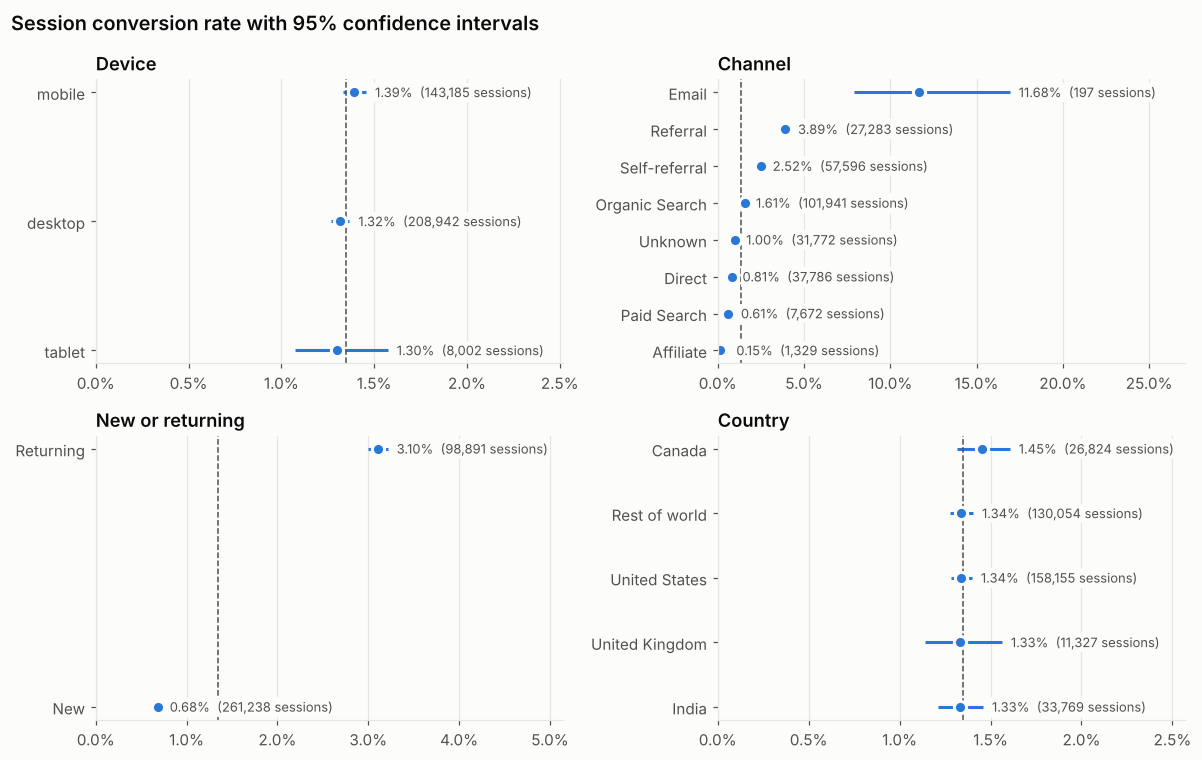

,dimension,segment,sessions,purchase_sessions,rate,ci_low,ci_high,aov,revenue_per_session
0,Device,desktop,208942,2749,0.0132,0.0127,0.0137,69.7659,0.8528
1,Device,mobile,143185,1995,0.0139,0.0133,0.0146,68.4454,0.8671
2,Device,tablet,8002,104,0.0130,0.0107,0.0157,63.8313,0.6621
3,Channel,Organic Search,101941,1638,0.0161,0.0153,0.0169,64.3730,0.9497
4,Channel,Self-referral,57596,1452,0.0252,0.0240,0.0265,74.6493,1.7406
5,Channel,Direct,37786,306,0.0081,0.0072,0.0091,73.8982,0.5378
6,Channel,Unknown,31772,318,0.0100,0.0090,0.0112,62.6000,0.5911
7,Channel,Referral,27283,1061,0.0389,0.0367,0.0412,69.2305,2.4436
8,Channel,Paid Search,7672,47,0.0061,0.0046,0.0081,68.8372,0.3858
9,Channel,Affiliate,1329,2,0.0015,0.0004,0.0055,83.5000,0.1257


In [4]:
DIMENSIONS = {"device_category": "Device", "channel": "Channel", "user_type": "New or returning", "country_group": "Country"}
seg_tables = []
for dim, label in DIMENSIONS.items():
    t = cs.rate_table(data_for(dim), dim).rename(columns={dim: "segment"})
    t.insert(0, "dimension", label)
    seg_tables.append(t)
segment_rates = pd.concat(seg_tables, ignore_index=True)
segment_rates.to_csv(OUT / "segment_conversion.csv", index=False)

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (label, t) in zip(axes.flat, segment_rates.groupby("dimension", sort=False)):
    t = t.sort_values("rate")
    y = np.arange(len(t))
    ax.errorbar(t["rate"], y, xerr=[t["rate"] - t["ci_low"], t["ci_high"] - t["rate"]], fmt="o",
                color=SERIES[0], ecolor=SERIES[0], elinewidth=2, capsize=0, markersize=8,
                markeredgecolor=SURFACE, markeredgewidth=2)
    for yi, (_, row) in zip(y, t.iterrows()):
        ax.annotate(f"{row['rate']:.2%}  ({row['sessions']:,.0f} sessions)", (row["ci_high"], yi),
                    xytext=(6, 0), textcoords="offset points", va="center", fontsize=8.5, color=INK_2,
                    bbox=dict(boxstyle="square,pad=0.15", fc=SURFACE, ec="none"))
    ax.axvline(SITE_RATE, color=INK_2, linestyle="--", linewidth=1)
    ax.set_yticks(y, t["segment"])
    ax.set_title(label)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
    ax.set_xlim(0, t["ci_high"].max() * 1.6)
    ax.grid(axis="y", visible=False)
fig.suptitle("Session conversion rate with 95% confidence intervals", x=0.01, ha="left", fontsize=13, fontweight="semibold")
fig.tight_layout()
fig.savefig(IMAGES / "analysis_conversion_by_segment.png")
plt.show()
segment_rates[["dimension", "segment", "sessions", "purchase_sessions", "rate", "ci_low", "ci_high", "aov", "revenue_per_session"]]

## 4. Which differences are real?

Devices are compared with desktop and returning visitors with new ones. Channels and countries have no natural baseline, so each is compared with all other sessions (for channels, all other sessions with a recorded source). p-values are Holm-adjusted within each dimension.

In [5]:
tests = cs.holm(pd.concat([
    cs.compare_segments(sessions, "device_category", reference="desktop"),
    cs.compare_segments(sessions, "user_type", reference="New"),
    cs.compare_segments(recorded, "channel"),
    cs.compare_segments(sessions, "country_group"),
    cs.compare_segments(sessions, "month", reference="2020-11"),
], ignore_index=True))
tests.to_csv(OUT / "significance_tests.csv", index=False)
tests[["dimension", "segment", "compared_with", "segment_rate", "comparison_rate", "difference",
       "diff_ci_low", "diff_ci_high", "relative_difference", "p_adjusted", "significant"]]

,dimension,segment,compared_with,segment_rate,comparison_rate,difference,diff_ci_low,diff_ci_high,relative_difference,p_adjusted,significant
0,device_category,mobile,desktop,0.0139,0.0132,0.0008,0.0000,0.0016,0.0590,0.0994,False
1,device_category,tablet,desktop,0.0130,0.0132,-0.0002,-0.0025,0.0026,-0.0122,0.9019,False
2,user_type,Returning,New,0.0310,0.0068,0.0242,0.0231,0.0254,3.5532,0.0000,True
3,channel,Organic Search,all other sessions,0.0161,0.0196,-0.0035,-0.0046,-0.0025,-0.1806,0.0000,True
4,channel,Self-referral,all other sessions,0.0252,0.0163,0.0089,0.0075,0.0103,0.5444,0.0000,True
5,channel,Direct,all other sessions,0.0081,0.0199,-0.0118,-0.0129,-0.0107,-0.5938,0.0000,True
6,channel,Unknown,all other sessions,0.0100,0.0194,-0.0094,-0.0105,-0.0081,-0.4833,0.0000,True
7,channel,Referral,all other sessions,0.0389,0.0159,0.0230,0.0207,0.0254,1.4477,0.0000,True
8,channel,Paid Search,all other sessions,0.0061,0.0186,-0.0125,-0.0141,-0.0104,-0.6708,0.0000,True
9,channel,Affiliate,all other sessions,0.0015,0.0183,-0.0168,-0.0180,-0.0128,-0.9179,0.0000,True


## 5. Where the funnel leaks

Closed funnel: each rate is the share of sessions at one step that went on to the next. In this sample the shipping step fires together with the start of checkout, so that step shows 100%.

Device steps are tested against desktop and new visitors' steps against returning visitors'. The chart shows the comparison with the larger gaps.

/usr/local/lib/python3.13/site-packages/statsmodels/stats/weightstats.py:838: RuntimeWarning: invalid value encountered in scalar divide
  zstat = value / std
/usr/local/lib/python3.13/site-packages/statsmodels/stats/weightstats.py:838: RuntimeWarning: invalid value encountered in scalar divide
  zstat = value / std


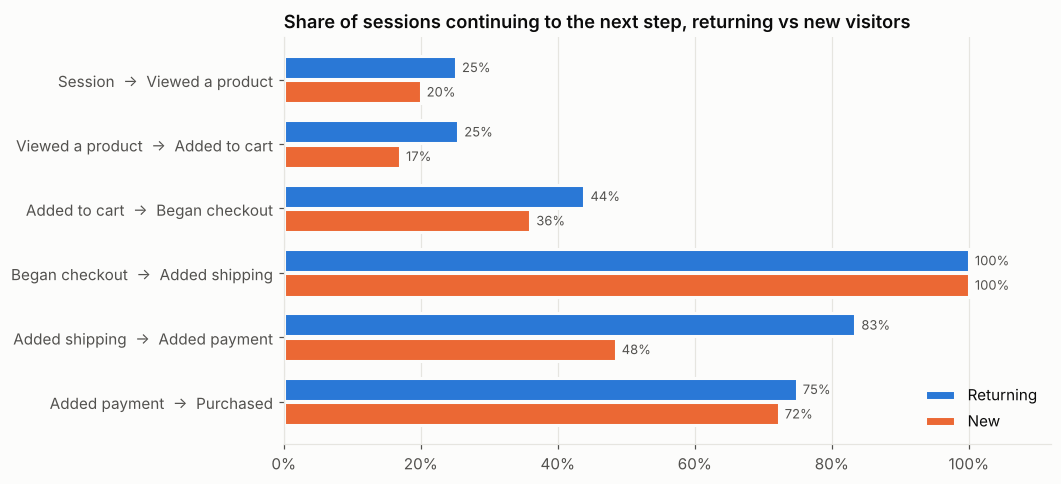

41% of sessions with a purchase skipped an earlier step in the same session (for example, the product was viewed in an earlier visit), so the closed funnel ends below total purchases.


,segment,step_number,step,sessions_reaching,rate_from_previous,rate_from_session,lost_from_previous
0,All,0,Session,360129,1.0000,1.0000,0.0000
1,All,1,Viewed a product,77020,0.2139,0.2139,"283,109.0000"
2,All,2,Added to cart,15173,0.1970,0.0421,"61,847.0000"
3,All,3,Began checkout,5959,0.3927,0.0165,"9,214.0000"
4,All,4,Added shipping,5959,1.0000,0.0165,0.0000
5,All,5,Added payment,3858,0.6474,0.0107,"2,101.0000"
6,All,6,Purchased,2848,0.7382,0.0079,"1,010.0000"


,segment,step,segment_rate,comparison_rate,difference,diff_ci_low,diff_ci_high,p_adjusted,significant
0,New,Session -> Viewed a product,0.1997,0.2513,-0.0516,-0.0547,-0.0485,0.0000,True
1,New,Viewed a product -> Added to cart,0.1696,0.2546,-0.0850,-0.0913,-0.0787,0.0000,True
2,New,Added to cart -> Began checkout,0.3598,0.4388,-0.0790,-0.0948,-0.0632,0.0000,True
3,New,Began checkout -> Added shipping,1.0000,1.0000,0.0000,-0.0012,0.0014,NaN,False
4,New,Added shipping -> Added payment,0.4844,0.8343,-0.3498,-0.3717,-0.3274,0.0000,True
5,New,Added payment -> Purchased,0.7224,0.7487,-0.0263,-0.0549,0.0020,0.1382,False


,segment,step,segment_rate,comparison_rate,difference,diff_ci_low,diff_ci_high,p_adjusted,significant
0,mobile,Session -> Viewed a product,0.2130,0.2145,-0.0015,-0.0042,0.0013,1.0000,False
1,tablet,Session -> Viewed a product,0.2124,0.2145,-0.0021,-0.0111,0.0072,1.0000,False
2,mobile,Viewed a product -> Added to cart,0.1991,0.1959,0.0032,-0.0026,0.0090,1.0000,False
3,tablet,Viewed a product -> Added to cart,0.1888,0.1959,-0.0071,-0.0253,0.0126,1.0000,False
4,mobile,Added to cart -> Began checkout,0.3959,0.3901,0.0058,-0.0101,0.0218,1.0000,False
5,tablet,Added to cart -> Began checkout,0.4050,0.3901,0.0149,-0.0384,0.0703,1.0000,False
6,mobile,Began checkout -> Added shipping,1.0000,1.0000,0.0000,-0.0016,0.0011,NaN,False
7,tablet,Began checkout -> Added shipping,1.0000,1.0000,0.0000,-0.0287,0.0011,NaN,False
8,mobile,Added shipping -> Added payment,0.6547,0.6412,0.0136,-0.0114,0.0384,1.0000,False
9,tablet,Added shipping -> Added payment,0.6769,0.6412,0.0358,-0.0502,0.1118,1.0000,False


In [6]:
funnel_all = cs.funnel_table(sessions)
funnel_device = cs.funnel_table(sessions, "device_category")
funnel_user = cs.funnel_table(sessions, "user_type")
step_tests = cs.funnel_step_tests(sessions, "device_category", reference="desktop")
user_step_tests = cs.funnel_step_tests(sessions, "user_type", reference="Returning")
funnel_all.to_csv(OUT / "funnel_overall.csv", index=False)
pd.concat([funnel_device, funnel_user]).to_csv(OUT / "funnel_by_segment.csv", index=False)
pd.concat([step_tests, user_step_tests]).to_csv(OUT / "funnel_step_tests.csv", index=False)

steps = funnel_all[funnel_all["step_number"] > 0]
biggest_leak = steps.loc[steps["lost_from_previous"].idxmax()]
lowest_step = steps.loc[steps["rate_from_previous"].idxmin()]
purchases_skipping = 1 - funnel_all["sessions_reaching"].iloc[-1] / sessions["purchase_sessions"].sum()

device_gap = step_tests["difference"].abs().max()
user_gap = user_step_tests["difference"].abs().max()
if user_gap >= device_gap:
    chart_data, chart_segments, chart_label = funnel_user, ["Returning", "New"], "returning vs new visitors"
else:
    chart_data, chart_segments, chart_label = funnel_device, ["desktop", "mobile"], "desktop vs mobile"
plot = chart_data[(chart_data["step_number"] > 0) & chart_data["segment"].isin(chart_segments)]
labels = list(plot["step"].unique())
y = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(9, 4.8))
for i, seg in enumerate(chart_segments):
    vals = plot[plot["segment"] == seg].set_index("step").loc[labels, "rate_from_previous"]
    bars = ax.barh(y + (i - 0.5) * 0.38, vals, height=0.36, color=SERIES[i], label=seg.title(),
                   edgecolor=SURFACE, linewidth=2)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in vals], padding=4, fontsize=8.5, color=INK_2)
ax.set_yticks(y, [f"{a_}  →  {b_}" for a_, b_ in zip(["Session"] + labels[:-1], labels)])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlim(0, 1.12)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title(f"Share of sessions continuing to the next step, {chart_label}")
fig.savefig(IMAGES / "analysis_funnel.png")
plt.show()
print(f"{purchases_skipping:.0%} of sessions with a purchase skipped an earlier step in the same session "
      "(for example, the product was viewed in an earlier visit), so the closed funnel ends below total purchases.")
display(funnel_all)
cols_ = ["segment", "step", "segment_rate", "comparison_rate", "difference", "diff_ci_low", "diff_ci_high", "p_adjusted", "significant"]
display(user_step_tests[cols_])
step_tests[cols_]

## 6. Cart abandonment

Share of sessions that added to cart but did not purchase.

In [7]:
abandon = []
for dim, label in DIMENSIONS.items():
    t = cs.rate_table(data_for(dim), dim, num="cart_purchase_sessions", den="add_to_cart_sessions").rename(columns={dim: "segment"})
    t.insert(0, "dimension", label)
    t["abandonment_rate"] = 1 - t["rate"]
    t["abandon_ci_low"], t["abandon_ci_high"] = 1 - t["ci_high"], 1 - t["ci_low"]
    abandon.append(t)
abandon = pd.concat(abandon, ignore_index=True)
cart_tests = cs.holm(pd.concat([
    cs.compare_segments(sessions, "device_category", num="cart_purchase_sessions", den="add_to_cart_sessions", reference="desktop", family="cart"),
    cs.compare_segments(sessions, "user_type", num="cart_purchase_sessions", den="add_to_cart_sessions", reference="New", family="cart"),
], ignore_index=True))
abandon.to_csv(OUT / "cart_abandonment.csv", index=False)
SITE_ABANDON = 1 - overall["cart_purchase_sessions"].iloc[0] / overall["add_to_cart_sessions"].iloc[0]
print(f"Site cart abandonment: {SITE_ABANDON:.1%}")
display(abandon[["dimension", "segment", "add_to_cart_sessions", "abandonment_rate", "abandon_ci_low", "abandon_ci_high"]])
cart_tests[["segment", "compared_with", "segment_rate", "comparison_rate", "difference", "p_adjusted", "significant"]]

Site cart abandonment: 81.2%


,dimension,segment,add_to_cart_sessions,abandonment_rate,abandon_ci_low,abandon_ci_high
0,Device,desktop,8790,0.8173,0.8091,0.8252
1,Device,mobile,6077,0.8058,0.7957,0.8156
2,Device,tablet,321,0.8069,0.7601,0.8463
3,Channel,Organic Search,5111,0.8135,0.8026,0.8240
4,Channel,Self-referral,3943,0.7956,0.7827,0.8079
5,Channel,Referral,2232,0.7021,0.6828,0.7207
6,Channel,Direct,1596,0.8810,0.8641,0.8959
7,Channel,Unknown,1376,0.8663,0.8473,0.8832
8,Channel,Paid Search,271,0.8930,0.8505,0.9245
9,Channel,Email,47,0.6170,0.4743,0.7421


,segment,compared_with,segment_rate,comparison_rate,difference,p_adjusted,significant
0,mobile,desktop,0.1942,0.1827,0.0115,0.1563,False
1,tablet,desktop,0.1931,0.1827,0.0104,0.6348,False
2,Returning,New,0.2737,0.1258,0.1479,0.0000,True


## 7. Order value

Order values are skewed by a few large orders, so means get bootstrap intervals and differences are tested with Mann-Whitney, which compares the whole distribution rather than only the mean. Orders whose session was not tracked are left out of the device and visitor comparisons.

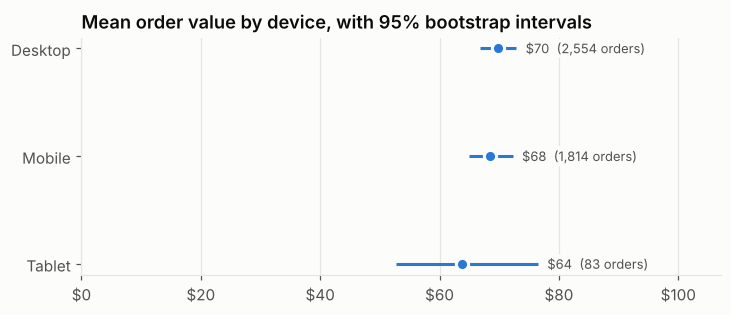

,dimension,segment,orders,mean_order_value,mean_ci_low,mean_ci_high,median_order_value,compared_with,difference,diff_ci_low,diff_ci_high,p_adjusted,significant
0,device_category,desktop,2554,69.7659,66.7858,72.8893,48.0000,NaN,NaN,NaN,NaN,NaN,False
1,device_category,mobile,1814,68.4454,64.8726,72.2784,47.0000,desktop,-1.3204,-6.0397,3.5417,0.5917,False
2,device_category,tablet,83,63.8313,52.6506,76.5181,50.0000,desktop,-5.9345,-17.6130,6.7210,0.9330,False
3,user_type,Returning,2862,71.5231,68.4416,74.7334,48.0000,New,6.7395,2.1115,11.2750,0.0027,True
4,user_type,New,1589,64.7835,61.6331,68.0882,46.0000,NaN,NaN,NaN,NaN,NaN,False
5,channel,Organic Search,1504,64.3730,60.8524,67.8857,45.0000,Direct,-9.5252,-21.6495,0.9594,0.0809,False
6,channel,Self-referral,1343,74.6493,69.6922,80.1728,50.0000,Direct,0.7511,-12.0542,12.6161,1.0000,False
7,channel,Referral,963,69.2305,65.0373,73.4071,48.0000,Direct,-4.6677,-17.0789,6.2559,1.0000,False
8,channel,Unknown,300,62.6000,56.9166,68.5500,46.0000,Direct,-11.2982,-24.6179,0.5133,1.0000,False
9,channel,Direct,275,73.8982,63.8943,85.4437,56.0000,NaN,NaN,NaN,NaN,NaN,False


In [8]:
tracked = orders[orders["device_category"] != "No session"]
aov_tests = pd.concat([
    cs.compare_order_values(tracked, "device_category", reference="desktop"),
    cs.compare_order_values(tracked, "user_type", reference="New"),
    cs.compare_order_values(tracked, "channel", reference="Direct"),
], ignore_index=True)
aov_tests.to_csv(OUT / "order_value_tests.csv", index=False)

dev_aov = aov_tests[aov_tests["dimension"] == "device_category"].sort_values("mean_order_value")
fig, ax = plt.subplots(figsize=(7.5, 2.8))
yy = np.arange(len(dev_aov))
ax.errorbar(dev_aov["mean_order_value"], yy,
            xerr=[dev_aov["mean_order_value"] - dev_aov["mean_ci_low"], dev_aov["mean_ci_high"] - dev_aov["mean_order_value"]],
            fmt="o", color=SERIES[0], elinewidth=2, capsize=0, markersize=8, markeredgecolor=SURFACE, markeredgewidth=2)
for yi, (_, row) in zip(yy, dev_aov.iterrows()):
    ax.annotate(f"${row['mean_order_value']:,.0f}  ({row['orders']:,} orders)", (row["mean_ci_high"], yi),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=8.5, color=INK_2,
                    bbox=dict(boxstyle="square,pad=0.15", fc=SURFACE, ec="none"))
ax.set_yticks(yy, dev_aov["segment"].str.title())
ax.set_xlim(0, dev_aov["mean_ci_high"].max() * 1.4)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.grid(axis="y", visible=False)
ax.set_title("Mean order value by device, with 95% bootstrap intervals")
fig.savefig(IMAGES / "analysis_order_value_by_device.png")
plt.show()
aov_tests[["dimension", "segment", "orders", "mean_order_value", "mean_ci_low", "mean_ci_high", "median_order_value",
           "compared_with", "difference", "diff_ci_low", "diff_ci_high", "p_adjusted", "significant"]]

## 8. Products

This section uses purchases only. In this sample, `view_item` and `add_to_cart` events carry long lists of products, so per-product view and add counts measure appearances in lists rather than a visitor looking at or adding that product. The cell below shows the size of the lists. Purchases are reliable: item revenue matches order revenue.

Categories are the merchandise groups assigned in dbt (`docs/data_model.md`), since the raw category labels differ between event types.

Item-list rows per session: 36 on product views, 44 on adds to cart. Item revenue $307,562 vs order revenue $307,640.
390 products sold. The top 36 brought half of item revenue; the top 20 brought 37%. Orders averaged 4.4 units.


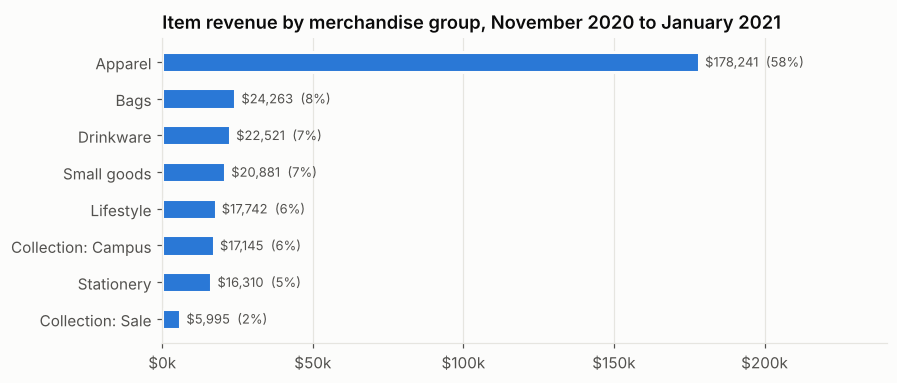

,item_category,products,orders_with_item,units_sold,item_revenue_usd,share_of_revenue,share_of_orders,avg_unit_price
0,Apparel,115,5084,6013,"178,241.0000",0.5795,1.1422,29.6426
1,Bags,31,738,1106,"24,263.0000",0.0789,0.1658,21.9376
2,Drinkware,26,980,1476,"22,521.0000",0.0732,0.2202,15.2581
3,Small goods,59,1641,2440,"20,881.0000",0.0679,0.3687,8.5578
4,Lifestyle,23,879,1657,"17,742.0000",0.0577,0.1975,10.7073
5,Collection: Campus,65,1288,1910,"17,145.0000",0.0557,0.2894,8.9764
6,Stationery,49,1882,4416,"16,310.0000",0.0530,0.4228,3.6934
7,Collection: Sale,17,241,280,"5,995.0000",0.0195,0.0541,21.4107
8,Gift cards,3,12,58,"2,475.0000",0.0080,0.0027,42.6724
9,Unknown,1,87,102,"1,931.0000",0.0063,0.0195,18.9314


month,2020-11-01,2020-12-01,2021-01-01
item_category,,,
Apparel,"$58,796","$86,518","$32,927"
Bags,"$5,812","$15,134","$3,317"
Drinkware,"$5,625","$13,278","$3,618"
Small goods,"$5,587","$10,182","$5,112"
Lifestyle,"$5,616","$8,407","$3,719"
Collection: Campus,"$4,800","$10,160","$2,185"
Stationery,"$4,118","$9,220","$2,972"
Collection: Sale,"$1,620","$3,632",$743
Gift cards,$50,"$1,225","$1,200"


,item_name,item_category,orders_with_item,units_sold,item_revenue_usd,share_of_revenue,avg_unit_price
0,Google Zip Hoodie F/C,Apparel,187,208,"10,488.0000",0.0341,50.4231
1,Google Crewneck Sweatshirt Navy,Apparel,196,217,"9,878.0000",0.0321,45.5207
2,Google Badge Heavyweight Pullover Black,Apparel,149,175,"8,444.0000",0.0275,48.2514
3,Google Men's Tech Fleece Grey,Apparel,87,107,"7,886.0000",0.0256,73.7009
4,Super G Unisex Joggers,Apparel,220,252,"7,826.0000",0.0254,31.0556
5,Google Crewneck Sweatshirt Green,Apparel,146,155,"7,095.0000",0.0231,45.7742
6,Google Men's Tech Fleece Vest Charcoal,Apparel,62,79,"5,234.0000",0.0170,66.2532
7,Google Men's Puff Jacket Black,Apparel,52,55,"5,221.0000",0.0170,94.9273
8,Google Sherpa Zip Hoodie Charcoal,Apparel,78,89,"4,953.0000",0.0161,55.6517
9,Google Canteen Bottle Black,Drinkware,128,248,"4,892.0000",0.0159,19.7258


In [9]:
items_per_view_session = products["item_views"].sum() / sessions["view_item_sessions"].sum()
items_per_cart_session = products["add_to_carts"].sum() / sessions["add_to_cart_sessions"].sum()
print(f"Item-list rows per session: {items_per_view_session:.0f} on product views, {items_per_cart_session:.0f} on adds to cart. "
      f"Item revenue {usd(products['item_revenue_usd'].sum())} vs order revenue {usd(orders['revenue_usd'].sum())}.")

prod = products.groupby(["item_name", "item_category"], as_index=False)[["orders_with_item", "units_sold", "item_revenue_usd"]].sum()
prod = prod[prod["item_revenue_usd"] > 0].sort_values("item_revenue_usd", ascending=False).reset_index(drop=True)
prod["share_of_revenue"] = prod["item_revenue_usd"] / prod["item_revenue_usd"].sum()
prod["cumulative_share"] = prod["share_of_revenue"].cumsum()
prod["avg_unit_price"] = prod["item_revenue_usd"] / prod["units_sold"]

cat = prod.groupby("item_category", as_index=False).agg(
    products=("item_name", "nunique"), orders_with_item=("orders_with_item", "sum"),
    units_sold=("units_sold", "sum"), item_revenue_usd=("item_revenue_usd", "sum"))
cat["share_of_revenue"] = cat["item_revenue_usd"] / cat["item_revenue_usd"].sum()
cat["share_of_orders"] = cat["orders_with_item"] / len(orders)
cat["avg_unit_price"] = cat["item_revenue_usd"] / cat["units_sold"]
cat = cat.sort_values("item_revenue_usd", ascending=False).reset_index(drop=True)

monthly_cat = products.groupby(["month", "item_category"], as_index=False)["item_revenue_usd"].sum()
monthly_cat = monthly_cat.pivot(index="item_category", columns="month", values="item_revenue_usd").fillna(0)
monthly_cat = monthly_cat.loc[cat["item_category"]]

PRODUCTS_FOR_HALF = int((prod["cumulative_share"] < 0.5).sum() + 1)
TOP20_SHARE = prod.head(20)["share_of_revenue"].sum()
items_per_order = orders["item_quantity"].mean()
cat.to_csv(OUT / "category_performance.csv", index=False)
prod.to_csv(OUT / "product_revenue.csv", index=False)
print(f"{len(prod)} products sold. The top {PRODUCTS_FOR_HALF} brought half of item revenue; the top 20 brought {TOP20_SHARE:.0%}. "
      f"Orders averaged {items_per_order:.1f} units.")

top = cat.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 3.6))
yy = np.arange(len(top))
bars = ax.barh(yy, top["item_revenue_usd"], height=0.55, color=SERIES[0], edgecolor=SURFACE, linewidth=2)
ax.bar_label(bars, labels=[f"${v:,.0f}  ({s_:.0%})" for v, s_ in zip(top["item_revenue_usd"], top["share_of_revenue"])],
             padding=4, fontsize=8.5, color=INK_2)
ax.set_yticks(yy, top["item_category"])
ax.set_xlim(0, top["item_revenue_usd"].max() * 1.35)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v / 1000:,.0f}k"))
ax.grid(axis="y", visible=False)
ax.set_title("Item revenue by merchandise group, November 2020 to January 2021")
fig.savefig(IMAGES / "analysis_category_revenue.png")
plt.show()
display(cat)
display(monthly_cat.style.format("${:,.0f}"))
prod.head(15)[["item_name", "item_category", "orders_with_item", "units_sold", "item_revenue_usd", "share_of_revenue", "avg_unit_price"]]

## 9. Customers

Three months is too short for lifetime value or cohort retention, so this section describes how concentrated revenue is among repeat buyers and which first-touch channels bring visitors who go on to buy.

Channels are also judged two ways. Per session, each visit is credited to the channel it came from. By first touch, a visitor is credited to the channel that first brought them, and the question is whether they ever bought in the three months. A channel that mostly brings people who buy on a later visit looks weak per session and strong by first touch.

In [10]:
repeat_rate = buyers["is_repeat_buyer"].mean()
repeat_rev_share = buyers.loc[buyers["is_repeat_buyer"], "revenue_usd"].sum() / buyers["revenue_usd"].sum()
top10 = buyers.sort_values("revenue_usd", ascending=False)
top10_share = top10.head(int(np.ceil(len(top10) * 0.10)))["revenue_usd"].sum() / top10["revenue_usd"].sum()
print(f"{len(buyers):,} buyers; {repeat_rate:.1%} ordered more than once and they brought {repeat_rev_share:.1%} of revenue. "
      f"The top 10% of buyers brought {top10_share:.1%}.")

seg_summary = segments.groupby("customer_segment", as_index=False)[["users", "buyers", "orders", "revenue_usd"]].sum()
seg_summary["share_of_revenue"] = seg_summary["revenue_usd"] / seg_summary["revenue_usd"].sum()
channel_buyers = segments.groupby("first_user_channel", as_index=False)[["users", "buyers", "revenue_usd"]].sum()
channel_buyers["visitor_to_buyer"] = channel_buyers["buyers"] / channel_buyers["users"]
channel_buyers["ci_low"], channel_buyers["ci_high"] = cs.wilson(channel_buyers["buyers"], channel_buyers["users"])
channel_buyers["revenue_per_visitor"] = channel_buyers["revenue_usd"] / channel_buyers["users"]
channel_buyers = channel_buyers.sort_values("users", ascending=False)
channel_buyers.to_csv(OUT / "first_channel_buyers.csv", index=False)

# Same channels judged two ways: per session, and by whether visitors they first brought ever bought.
session_view = cs.rate_table(recorded, "channel")[["channel", "sessions", "rate"]].rename(
    columns={"channel": "channel", "rate": "session_conversion"})
attribution = session_view.merge(channel_buyers[["first_user_channel", "users", "visitor_to_buyer", "ci_low", "ci_high"]]
                                 .rename(columns={"first_user_channel": "channel", "users": "first_touch_visitors"}),
                                 on="channel", how="inner")
attribution.to_csv(OUT / "channel_attribution.csv", index=False)
print("Channels judged per session versus by the visitors they first brought:")
display(attribution)
display(seg_summary)
channel_buyers

3,702 buyers; 11.9% ordered more than once and they brought 24.8% of revenue. The top 10% of buyers brought 36.5%.
Channels judged per session versus by the visitors they first brought:


,channel,sessions,session_conversion,first_touch_visitors,visitor_to_buyer,ci_low,ci_high
0,Organic Search,101941,0.0161,101742,0.0131,0.0124,0.0138
1,Self-referral,57596,0.0252,14763,0.0180,0.0159,0.0202
2,Direct,37786,0.0081,64109,0.0132,0.0123,0.0141
3,Unknown,31772,0.0100,50001,0.0149,0.0138,0.0160
4,Referral,27283,0.0389,25257,0.0134,0.0121,0.0149
5,Paid Search,7672,0.0061,14282,0.0127,0.0110,0.0146


,customer_segment,users,buyers,orders,revenue_usd,share_of_revenue
0,Non-buyer,266452,0,0,0.0000,0.0000
1,"One-time, lapsed",2534,2534,2534,"183,250.0000",0.5957
2,"One-time, recent",729,729,729,"48,048.0000",0.1562
3,"Repeat, lapsing",353,353,967,"64,706.0000",0.2103
4,"Repeat, recent",86,86,221,"11,636.0000",0.0378


,first_user_channel,users,buyers,revenue_usd,visitor_to_buyer,ci_low,ci_high,revenue_per_visitor
1,Organic Search,101742,1330,"106,981.0000",0.0131,0.0124,0.0138,1.0515
0,Direct,64109,844,"71,535.0000",0.0132,0.0123,0.0141,1.1158
5,Unknown,50001,743,"64,161.0000",0.0149,0.0138,0.0160,1.2832
3,Referral,25257,339,"26,645.0000",0.0134,0.0121,0.0149,1.0550
4,Self-referral,14763,265,"22,764.0000",0.0180,0.0159,0.0202,1.5420
2,Paid Search,14282,181,"15,554.0000",0.0127,0.0110,0.0146,1.0891


## 10. What closing the gaps would be worth

Each estimate takes a gap found significant above and asks what the store would gain over these three months if part of it closed. Assumptions:
- **Scenarios:** 10%, 25% (central) and 50% of the gap closed. Closing the whole gap is not assumed: returning visitors arrive with more intent, so part of their advantage is who they are, not what the site does.
- **Value of a conversion:** each segment's own revenue per converting session.
- **Funnel steps:** extra sessions passing a step go on to purchase at that segment's own rate from that step onward.
- **New visitors' carts:** the share of new visitors' carts that end in a purchase in the same session, moved toward returning visitors' share.
- **Not sized:** paid search (it converts poorly per session but its visitors buy as often as organic search's later on; see section 9), and products (view and add data are not reliable per product; see section 8). The dataset has no costs, so these are revenue estimates, not profit.
- Estimates overlap (a better checkout is part of better cart completion), so they are alternatives, not a total. November to January includes the holiday peak, so annualising would overstate them.

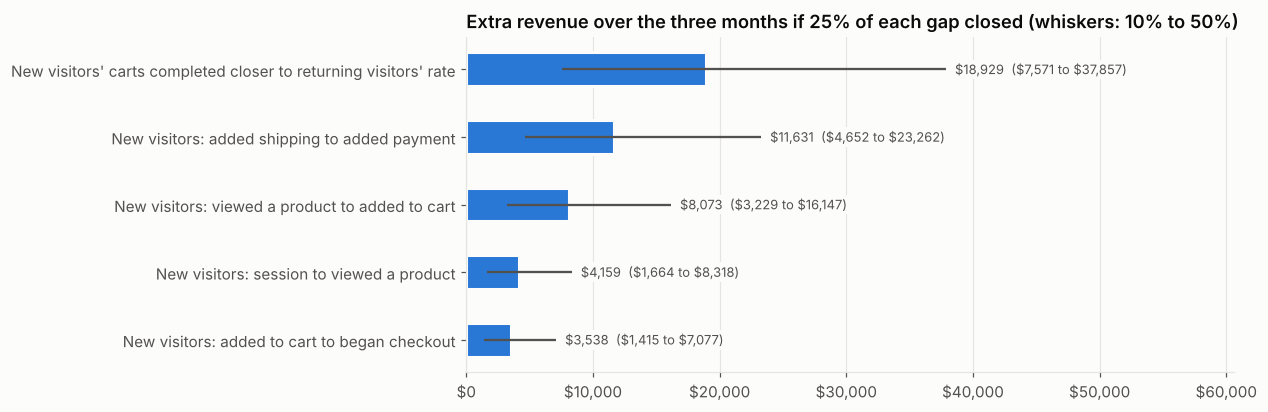

For scale: counted order revenue in the period was $307,640.


,opportunity,lever,segment,baseline_rate,target_rate,trials,extra_conversions_10pct,extra_revenue_10pct,extra_conversions_25pct,extra_revenue_25pct,extra_conversions_50pct,extra_revenue_50pct
0,New visitors' carts completed closer to return...,Cart,New,0.1258,0.2737,"8,853.0000",130.9221,"7,571.4871",327.3051,"18,928.7176",654.6103,"37,857.4353"
1,New visitors: added shipping to added payment,Funnel step,New,0.4844,0.8343,"3,183.0000",111.3558,"4,652.4520",278.3894,"11,631.1299",556.7788,"23,262.2598"
2,New visitors: viewed a product to added to cart,Funnel step,New,0.1696,0.2546,"52,171.0000",443.4571,"3,229.3053","1,108.6426","8,073.2633","2,217.2853","16,146.5267"
3,New visitors: session to viewed a product,Funnel step,New,0.1997,0.2513,"261,238.0000","1,347.2012","1,663.6304","3,368.0029","4,159.0761","6,736.0058","8,318.1522"
4,New visitors: added to cart to began checkout,Funnel step,New,0.3598,0.4388,"8,847.0000",69.9275,"1,415.3536",174.8188,"3,538.3841",349.6375,"7,076.7682"


In [11]:
FRACTIONS = (0.10, 0.25, 0.50)
opps = []

def step_opportunities(tests_, funnel_, by, reference):
    rates = cs.rate_table(sessions, by).set_index(by)
    fx = funnel_.set_index(["segment", "step"])
    for _, t in tests_[(tests_["significant"]) & (tests_["difference"] < 0)].iterrows():
        seg = t["segment"]
        prev_step, step = t["step"].split(" -> ")
        trials = fx.loc[(seg, prev_step), "sessions_reaching"]
        reaching = fx.loc[(seg, step), "sessions_reaching"]
        last = fx.loc[(seg, cs.FUNNEL[-1][1]), "sessions_reaching"]
        onward = last / reaching if reaching else 0
        value = rates.loc[seg, "revenue_per_conversion"] * min(onward, 1)
        opps.append({"opportunity": f"{seg.title()} visitors: {prev_step.lower()} to {step.lower()}",
                     "lever": "Funnel step", "segment": seg, "baseline_rate": t["segment_rate"],
                     "target_rate": t["comparison_rate"], "trials": trials,
                     **cs.size_gap(trials, t["segment_rate"], t["comparison_rate"], value, FRACTIONS)})

dev = cs.rate_table(sessions, "device_category").set_index("device_category")
dev_tests = tests[tests["dimension"] == "device_category"].set_index("segment")
for seg, row in dev.iterrows():
    if seg != "desktop" and seg in dev_tests.index and dev_tests.loc[seg, "significant"] and dev_tests.loc[seg, "difference"] < 0:
        opps.append({"opportunity": f"{seg.title()} conversion closer to desktop", "lever": "Whole session",
                     "segment": seg, "baseline_rate": row["rate"], "target_rate": dev.loc["desktop", "rate"],
                     "trials": row["sessions"],
                     **cs.size_gap(row["sessions"], row["rate"], dev.loc["desktop", "rate"], row["revenue_per_conversion"], FRACTIONS)})
step_opportunities(step_tests, funnel_device, "device_category", "desktop")
step_opportunities(user_step_tests, funnel_user, "user_type", "Returning")

ut = cs.rate_table(sessions, "user_type", num="cart_purchase_sessions", den="add_to_cart_sessions").set_index("user_type")
ct = cart_tests[cart_tests["dimension"] == "user_type"]
if {"New", "Returning"} <= set(ut.index) and len(ct) and ct.iloc[0]["significant"] and ut.loc["New", "rate"] < ut.loc["Returning", "rate"]:
    new = ut.loc["New"]
    opps.append({"opportunity": "New visitors' carts completed closer to returning visitors' rate", "lever": "Cart",
                 "segment": "New", "baseline_rate": new["rate"], "target_rate": ut.loc["Returning", "rate"],
                 "trials": new["add_to_cart_sessions"],
                 **cs.size_gap(new["add_to_cart_sessions"], new["rate"], ut.loc["Returning", "rate"],
                               new["revenue_per_conversion"], FRACTIONS)})

opportunities = pd.DataFrame(opps).sort_values("extra_revenue_25pct", ascending=False).reset_index(drop=True)
opportunities.to_csv(OUT / "opportunities.csv", index=False)
period_revenue = r.order_revenue_usd

if len(opportunities):
    o = opportunities.head(8).iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, 0.55 * len(o) + 1.2))
    yy = np.arange(len(o))
    ax.barh(yy, o["extra_revenue_25pct"], height=0.5, color=SERIES[0], edgecolor=SURFACE, linewidth=2)
    ax.errorbar(o["extra_revenue_25pct"], yy, xerr=[o["extra_revenue_25pct"] - o["extra_revenue_10pct"],
                o["extra_revenue_50pct"] - o["extra_revenue_25pct"]], fmt="none", ecolor=INK_2, elinewidth=1.5)
    for yi, (_, row) in zip(yy, o.iterrows()):
        ax.annotate(f"${row['extra_revenue_25pct']:,.0f}  (${row['extra_revenue_10pct']:,.0f} to ${row['extra_revenue_50pct']:,.0f})",
                    (row["extra_revenue_50pct"], yi), xytext=(6, 0), textcoords="offset points", va="center", fontsize=8.5, color=INK_2,
                    bbox=dict(boxstyle="square,pad=0.15", fc=SURFACE, ec="none"))
    ax.set_yticks(yy, o["opportunity"])
    ax.set_xlim(0, o["extra_revenue_50pct"].max() * 1.6)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
    ax.grid(axis="y", visible=False)
    ax.set_title("Extra revenue over the three months if 25% of each gap closed (whiskers: 10% to 50%)")
    fig.savefig(IMAGES / "analysis_opportunities.png")
    plt.show()
print(f"For scale: counted order revenue in the period was {usd(period_revenue)}.")
opportunities

## 11. How to test the main fix

The largest gap is new visitors adding payment details after shipping. A change there (for example guest checkout or express wallets) should be tested before it is rolled out. This cell works out how many new visitors reaching the shipping step an A/B test needs per variant to detect each scenario's improvement with 80% power at a 5% significance level, and how long that takes at this period's traffic with a 50/50 split.

In [12]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

pay = user_step_tests[(user_step_tests["segment"] == "New") & (user_step_tests["step"] == "Added shipping -> Added payment")].iloc[0]
new_at_shipping_per_month = funnel_user.set_index(["segment", "step"]).loc[("New", "Added shipping"), "sessions_reaching"] / sessions["month"].nunique()
plan = []
for f in FRACTIONS:
    target = pay["segment_rate"] + f * (pay["comparison_rate"] - pay["segment_rate"])
    n = NormalIndPower().solve_power(proportion_effectsize(target, pay["segment_rate"]), alpha=0.05, power=0.8, ratio=1)
    plan.append({"gap_closed": f, "baseline_rate": pay["segment_rate"], "target_rate": target,
                 "sessions_per_variant": int(np.ceil(n)), "weeks_at_current_traffic": 2 * n / new_at_shipping_per_month * 52 / 12})
test_plan = pd.DataFrame(plan)
test_plan.to_csv(OUT / "ab_test_plan.csv", index=False)
print(f"About {new_at_shipping_per_month:,.0f} new visitors a month reach the shipping step.")
test_plan

About 1,061 new visitors a month reach the shipping step.


,gap_closed,baseline_rate,target_rate,sessions_per_variant,weeks_at_current_traffic
0,0.1000,0.4844,0.5194,3206,26.1805
1,0.2500,0.4844,0.5719,511,4.1665
2,0.5000,0.4844,0.6594,125,1.0145


## 12. Summary

Generated from the results above and saved to `data/exports/analysis/summary.md`.

In [13]:
def test_line(dim, seg):
    t = tests[(tests["dimension"] == dim) & (tests["segment"] == seg)]
    if t.empty:
        return "not tested"
    t = t.iloc[0]
    return (f"{pct(t['segment_rate'])} vs {pct(t['comparison_rate'])} ({t['compared_with']}), difference {pp(t['difference'])} "
            f"[95% CI {pp(t['diff_ci_low'])} to {pp(t['diff_ci_high'])}], adjusted p = {t['p_adjusted']:.3g}"
            f"{'' if t['significant'] else ', not significant'}")

ch = tests[tests["dimension"] == "channel"].sort_values("segment_rate")
sig_ch = ch[ch["significant"]]
lines = [
    f"- **Overall:** {overall['sessions'].iloc[0]:,.0f} sessions, conversion {pct(SITE_RATE)}, {overall['orders'].iloc[0]:,.0f} orders, "
    f"{usd(overall['revenue_usd'].iloc[0])} revenue in tracked sessions, mean order {usd(SITE_AOV)}, revenue per session ${overall['revenue_per_session'].iloc[0]:.2f}.",
    f"- **Data quality:** {quality.loc['Duplicate events', 'share_of_raw_revenue']:.1%} of raw purchase revenue was duplicate events and "
    f"{quality.loc['No usable transaction ID', 'share_of_raw_revenue']:.1%} had no usable transaction ID; both are excluded from revenue.",
    f"- **Traffic sources:** self-referrals from the store's own domain were {SELF_REF_SESSION_SHARE:.1%} of sessions and {SELF_REF_REVENUE_SHARE:.1%} of revenue; "
    f"{NOT_REC_SESSION_SHARE:.1%} of sessions had no recorded source and {NOT_REC['purchase_sessions']:,.0f} of them had a purchase.",
    f"- **By month:** " + "; ".join(f"{m.month} {pct(m.rate)}" for m in monthly.itertuples()) + ".",
]
for seg in [s for s in dev.index if s != "desktop"]:
    lines.append(f"- **{seg.title()} vs desktop:** {test_line('device_category', seg)}.")
lines.append(f"- **Returning vs new:** {test_line('user_type', 'Returning')}.")
if len(sig_ch):
    lines.append("- **Channels significantly different from the rest:** " + "; ".join(
        f"{r_.segment} {pct(r_.segment_rate)} ({pp(r_.difference)})" for r_ in sig_ch.itertuples()) + ".")
lines.append("- **Closed funnel, share continuing at each step:** " + "; ".join(
    f"{r_.step} {r_.rate_from_previous:.1%}" for r_ in steps.itertuples()) + ".")
lines.append(f"- **Purchases outside the closed funnel:** {purchases_skipping:.0%} of sessions with a purchase skipped an earlier step in that session.")
lines.append(f"- **Biggest funnel loss:** {int(biggest_leak['lost_from_previous']):,} sessions lost at "
             f"'{biggest_leak['step']}' ({biggest_leak['rate_from_previous']:.1%} continue). Lowest step rate: "
             f"'{lowest_step['step']}' at {lowest_step['rate_from_previous']:.1%}.")
for name_, tt in [("a device differs from desktop", step_tests), ("new visitors differ from returning", user_step_tests)]:
    sig_steps = tt[tt["significant"]]
    lines.append(f"- **Funnel steps where {name_}:** " + ("; ".join(
        f"{r_.segment} {r_.step.lower()} {pct(r_.segment_rate)} vs {pct(r_.comparison_rate)} ({pp(r_.difference)})"
        for r_ in sig_steps.itertuples()) if len(sig_steps) else "none") + ".")
lines.append(f"- **Cart abandonment:** {SITE_ABANDON:.1%} of sessions that added to cart did not buy in the same session.")
for t_ in cart_tests.itertuples():
    lines.append(f"- **Cart completion, {t_.segment} vs {t_.compared_with}:** {pct(t_.segment_rate)} vs {pct(t_.comparison_rate)} "
                 f"({pp(t_.difference)}, adjusted p = {t_.p_adjusted:.3g}{'' if t_.significant else ', not significant'}).")
lines.append("- **Channels per session vs by first touch:** " + "; ".join(
    f"{r_.channel} {pct(r_.session_conversion)} per session, {pct(r_.visitor_to_buyer)} of first-touch visitors bought"
    for r_ in attribution.itertuples()) + ".")
sig_aov = aov_tests[aov_tests["significant"] == True]
lines.append("- **Order value:** " + ("; ".join(
    f"{r_.segment} ${r_.mean_order_value:,.0f} vs {r_.compared_with} ({'+' if r_.difference >= 0 else '-'}${abs(r_.difference):,.0f})"
    for r_ in sig_aov.itertuples()) if len(sig_aov) else "no significant differences by device, visitor type or channel") + ".")
lines.append(f"- **Product data:** {items_per_view_session:.0f} item-list rows per session on product views and {items_per_cart_session:.0f} on adds to cart, so only purchases are used per product.")
lines.append(f"- **Products:** {len(prod)} sold; top {PRODUCTS_FOR_HALF} brought half of item revenue, top 20 brought {TOP20_SHARE:.0%}. Groups: " + "; ".join(
    f"{r_.item_category} {r_.share_of_revenue:.0%}" for r_ in cat.head(6).itertuples()) + ".")
lines.append(f"- **Customers:** {repeat_rate:.1%} of {len(buyers):,} buyers ordered more than once, bringing {repeat_rev_share:.1%} of revenue; "
             f"the top 10% of buyers brought {top10_share:.1%}.")
for o_ in opportunities.head(6).itertuples():
    lines.append(f"- **Opportunity, {o_.opportunity}:** {usd(o_.extra_revenue_25pct)} over the three months at 25% of the gap "
                 f"({usd(o_.extra_revenue_10pct)} to {usd(o_.extra_revenue_50pct)}); counted revenue was {usd(period_revenue)}.")
tp = test_plan[test_plan["gap_closed"] == 0.25].iloc[0]
lines.append(f"- **Test plan:** detecting new visitors' payment step rising from {pct(tp.baseline_rate)} to {pct(tp.target_rate)} (25% of the gap) needs "
             f"{int(tp.sessions_per_variant):,} sessions reaching shipping per variant, about {tp.weeks_at_current_traffic:.0f} weeks at this period's traffic.")
summary = "\n".join(lines)
(OUT / "summary.md").write_text("# Analysis summary\n\n" + summary + "\n")
display(Markdown(summary))

- **Overall:** 360,129 sessions, conversion 1.35%, 4,451 orders, $307,640 revenue in tracked sessions, mean order $69, revenue per session $0.85.
- **Data quality:** 6.3% of raw purchase revenue was duplicate events and 8.8% had no usable transaction ID; both are excluded from revenue.
- **Traffic sources:** self-referrals from the store's own domain were 16.0% of sessions and 32.6% of revenue; 26.3% of sessions had no recorded source and 1 of them had a purchase.
- **By month:** 2020-11 1.49%; 2020-12 1.59%; 2021-01 0.94%.
- **Mobile vs desktop:** 1.39% vs 1.32% (desktop), difference +0.08 pp [95% CI +0.00 pp to +0.16 pp], adjusted p = 0.0994, not significant.
- **Tablet vs desktop:** 1.30% vs 1.32% (desktop), difference -0.02 pp [95% CI -0.25 pp to +0.26 pp], adjusted p = 0.902, not significant.
- **Returning vs new:** 3.10% vs 0.68% (New), difference +2.42 pp [95% CI +2.31 pp to +2.54 pp], adjusted p = 0.
- **Channels significantly different from the rest:** Affiliate 0.15% (-1.68 pp); Paid Search 0.61% (-1.25 pp); Direct 0.81% (-1.18 pp); Unknown 1.00% (-0.94 pp); Organic Search 1.61% (-0.35 pp); Self-referral 2.52% (+0.89 pp); Referral 3.89% (+2.30 pp); Email 11.68% (+9.86 pp).
- **Closed funnel, share continuing at each step:** Viewed a product 21.4%; Added to cart 19.7%; Began checkout 39.3%; Added shipping 100.0%; Added payment 64.7%; Purchased 73.8%.
- **Purchases outside the closed funnel:** 41% of sessions with a purchase skipped an earlier step in that session.
- **Biggest funnel loss:** 283,109 sessions lost at 'Viewed a product' (21.4% continue). Lowest step rate: 'Added to cart' at 19.7%.
- **Funnel steps where a device differs from desktop:** none.
- **Funnel steps where new visitors differ from returning:** New session -> viewed a product 19.97% vs 25.13% (-5.16 pp); New viewed a product -> added to cart 16.96% vs 25.46% (-8.50 pp); New added to cart -> began checkout 35.98% vs 43.88% (-7.90 pp); New added shipping -> added payment 48.44% vs 83.43% (-34.98 pp).
- **Cart abandonment:** 81.2% of sessions that added to cart did not buy in the same session.
- **Cart completion, mobile vs desktop:** 19.42% vs 18.27% (+1.15 pp, adjusted p = 0.156, not significant).
- **Cart completion, tablet vs desktop:** 19.31% vs 18.27% (+1.04 pp, adjusted p = 0.635, not significant).
- **Cart completion, Returning vs New:** 27.37% vs 12.58% (+14.79 pp, adjusted p = 8.21e-117).
- **Channels per session vs by first touch:** Organic Search 1.61% per session, 1.31% of first-touch visitors bought; Self-referral 2.52% per session, 1.80% of first-touch visitors bought; Direct 0.81% per session, 1.32% of first-touch visitors bought; Unknown 1.00% per session, 1.49% of first-touch visitors bought; Referral 3.89% per session, 1.34% of first-touch visitors bought; Paid Search 0.61% per session, 1.27% of first-touch visitors bought.
- **Order value:** Returning $72 vs New (+$7).
- **Product data:** 36 item-list rows per session on product views and 44 on adds to cart, so only purchases are used per product.
- **Products:** 390 sold; top 36 brought half of item revenue, top 20 brought 37%. Groups: Apparel 58%; Bags 8%; Drinkware 7%; Small goods 7%; Lifestyle 6%; Collection: Campus 6%.
- **Customers:** 11.9% of 3,702 buyers ordered more than once, bringing 24.8% of revenue; the top 10% of buyers brought 36.5%.
- **Opportunity, New visitors' carts completed closer to returning visitors' rate:** $18,929 over the three months at 25% of the gap ($7,571 to $37,857); counted revenue was $307,640.
- **Opportunity, New visitors: added shipping to added payment:** $11,631 over the three months at 25% of the gap ($4,652 to $23,262); counted revenue was $307,640.
- **Opportunity, New visitors: viewed a product to added to cart:** $8,073 over the three months at 25% of the gap ($3,229 to $16,147); counted revenue was $307,640.
- **Opportunity, New visitors: session to viewed a product:** $4,159 over the three months at 25% of the gap ($1,664 to $8,318); counted revenue was $307,640.
- **Opportunity, New visitors: added to cart to began checkout:** $3,538 over the three months at 25% of the gap ($1,415 to $7,077); counted revenue was $307,640.
- **Test plan:** detecting new visitors' payment step rising from 48.44% to 57.19% (25% of the gap) needs 511 sessions reaching shipping per variant, about 4 weeks at this period's traffic.